Step 1: Downloading MIT-BIH Database...
Step 2: Installing Dependencies (WFDB, SHAP)...
Using Device: cuda
Loading Training Data (from 37 patients)...
Loading Test Data (from 10 patients)...
Train Shape: (85420, 1, 256) | Test Shape: (21823, 1, 256)
Starting Training...
Epoch 1/30 | Loss: 0.1757 | Acc: 93.68%
Epoch 2/30 | Loss: 0.0922 | Acc: 96.67%
Epoch 3/30 | Loss: 0.0646 | Acc: 97.66%
Epoch 4/30 | Loss: 0.0575 | Acc: 97.99%
Epoch 5/30 | Loss: 0.0472 | Acc: 98.34%
Epoch 6/30 | Loss: 0.0395 | Acc: 98.59%
Epoch 7/30 | Loss: 0.0374 | Acc: 98.73%
Epoch 8/30 | Loss: 0.0323 | Acc: 98.91%
Epoch 9/30 | Loss: 0.0290 | Acc: 99.04%
Epoch 10/30 | Loss: 0.0286 | Acc: 99.09%
Epoch 11/30 | Loss: 0.0241 | Acc: 99.21%
Epoch 12/30 | Loss: 0.0227 | Acc: 99.23%
Epoch 13/30 | Loss: 0.0208 | Acc: 99.34%
Epoch 14/30 | Loss: 0.0208 | Acc: 99.34%
Epoch 15/30 | Loss: 0.0191 | Acc: 99.37%
Epoch 16/30 | Loss: 0.0174 | Acc: 99.43%
Epoch 17/30 | Loss: 0.0184 | Acc: 99.39%
Epoch 18/30 | Loss: 0.0145 | Acc: 99.52%


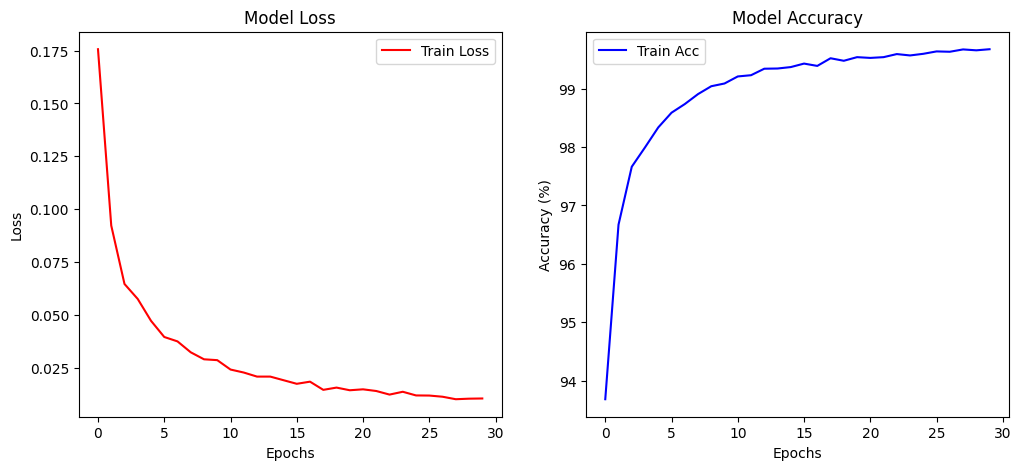


Classification Report (Test Set):
              precision    recall  f1-score   support

  Normal (N)       0.96      0.79      0.87     18528
    SVEB (S)       0.04      0.15      0.06       412
     VEB (V)       0.32      0.94      0.47       801
  Fusion (F)       0.00      0.00      0.00        16
 Unknown (Q)       1.00      0.84      0.91      2066

    accuracy                           0.79     21823
   macro avg       0.46      0.54      0.46     21823
weighted avg       0.92      0.79      0.84     21823



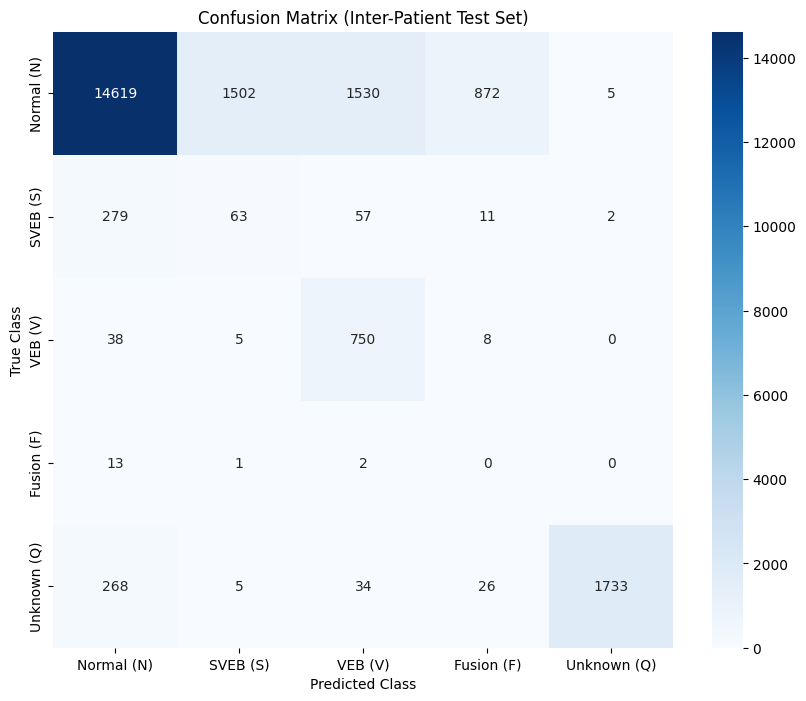

/tmp/ipykernel_1936/3237747714.py:290: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  heatmap = np.maximum(heatmap.cpu(), 0) # ReLU


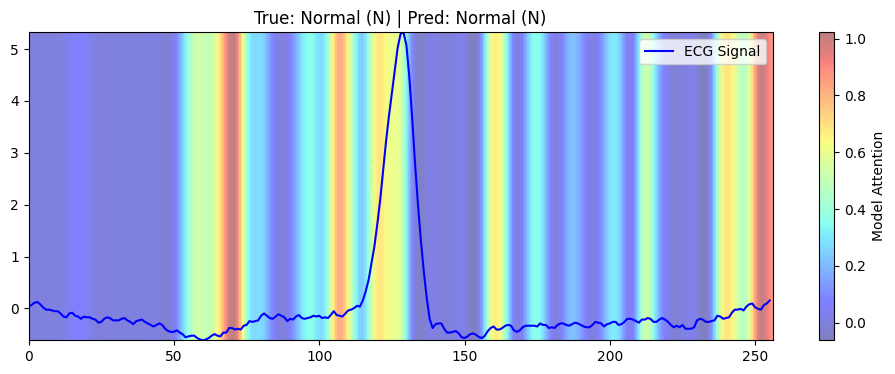

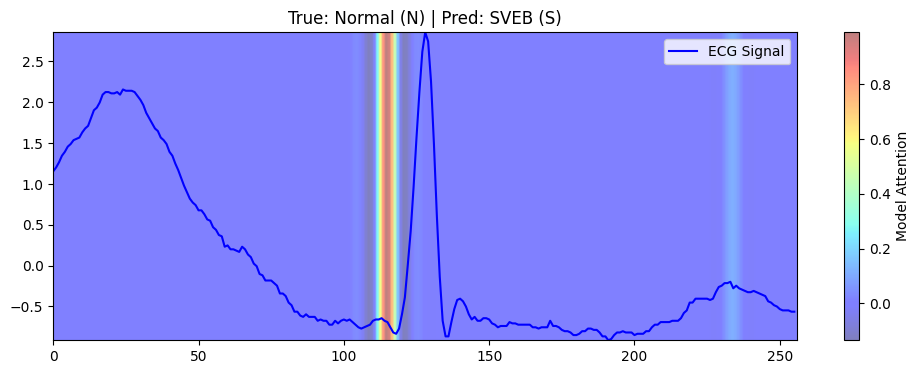

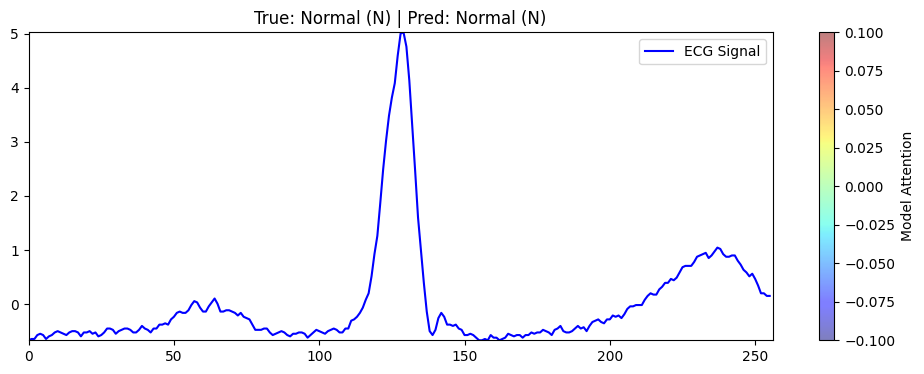

In [ ]:
 # ==========================================
# 1. INSTALLATION & SETUP
# ==========================================
import os
import shutil

# Clean previous runs
if os.path.exists('mit-bih-arrhythmia-database-1.0.0'):
    shutil.rmtree('mit-bih-arrhythmia-database-1.0.0')

print("Step 1: Downloading MIT-BIH Database...")
!wget -q -r -N -c -np https://physionet.org/files/mitdb/1.0.0/

# Move files to a clean folder
source_dir = 'physionet.org/files/mitdb/1.0.0'
destination_dir = 'mit-bih-arrhythmia-database-1.0.0'
if not os.path.exists(destination_dir):
    shutil.move(source_dir, destination_dir)

print("Step 2: Installing Dependencies (WFDB, SHAP)...")
!pip install -q wfdb shap

# ==========================================
# 2. IMPORTS
# ==========================================
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import shap

# Set Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# ==========================================
# 3. ROBUST DATA LOADING (THE FIXES)
# ==========================================
# FIX 1: Inter-Patient Split (Crucial for Thesis validity)
all_records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '219', '220', '221', '222',
    '223', '228', '230', '231', '232', '233', '234'
]

# Split patient IDs, not beats
train_patients, test_patients = train_test_split(all_records, test_size=0.2, random_state=42)

def load_data_safe(records_list, database_path='mit-bih-arrhythmia-database-1.0.0/'):
    X = []
    y = []

    # AAMI Mapping (Standard Medical Classes)
    aami_dict = {
        'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,  # Normal
        'A': 1, 'a': 1, 'J': 1, 'S': 1,          # SVEB (Supraventricular)
        'V': 2, 'E': 2,                          # VEB (Ventricular)
        'F': 3,                                  # Fusion
        '/': 4, 'f': 4, 'Q': 4                   # Unknown
    }

    for record_name in records_list:
        try:
            path = os.path.join(database_path, record_name)
            record = wfdb.rdrecord(path)
            annotation = wfdb.rdann(path, 'atr')

            # Use Lead 0 (MLII)
            signal = record.p_signal[:, 0]

            for sample_idx, symbol in zip(annotation.sample, annotation.symbol):
                if symbol in aami_dict:
                    # Window: 128 before, 128 after (Total 256)
                    start, end = sample_idx - 128, sample_idx + 128
                    if start >= 0 and end < len(signal):
                        beat = signal[start:end]

                        # FIX 2: Per-Beat Z-Score Normalization
                        beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-6)

                        X.append(beat)
                        y.append(aami_dict[symbol])
        except Exception as e:
            continue

    return np.array(X), np.array(y)

print(f"Loading Training Data (from {len(train_patients)} patients)...")
X_train, y_train = load_data_safe(train_patients)
print(f"Loading Test Data (from {len(test_patients)} patients)...")
X_test, y_test = load_data_safe(test_patients)

# Reshape for PyTorch (Batch, Channel, Length)
X_train = X_train.reshape(-1, 1, 256)
X_test = X_test.reshape(-1, 1, 256)

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

# ==========================================
# 4. CLASS BALANCING & DATALOADERS
# ==========================================
train_data = TensorDataset(torch.Tensor(X_train), torch.LongTensor(y_train))
test_data = TensorDataset(torch.Tensor(X_test), torch.LongTensor(y_test))

# FIX 3: Weighted Random Sampler (Balances the classes)
class_counts = np.bincount(y_train)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in y_train]

sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_data, batch_size=64, sampler=sampler, num_workers=2)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False, num_workers=2)

# ==========================================
# 5. MODEL DEFINITION
# ==========================================
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(SimpleCNN, self).__init__()
        # Conv Block 1
        self.conv1 = nn.Conv1d(1, 32, kernel_size=5)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)

        # Conv Block 2 (We will hook Grad-CAM here)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5)
        self.bn2 = nn.BatchNorm1d(64)
        self.pool2 = nn.MaxPool1d(2)

        # Conv Block 3
        self.conv3 = nn.Conv1d(64, 128, kernel_size=3)
        self.bn3 = nn.BatchNorm1d(128)
        self.pool3 = nn.MaxPool1d(2)

        # Fully Connected
        self.fc1 = nn.Linear(128 * 29, 128) # Calculated based on input 256
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 6. TRAINING LOOP WITH GRAPHS
# ==========================================
history = {'train_loss': [], 'train_acc': []}
EPOCHS = 30  # Increase this to 10-20 for better results

print("Starting Training...")
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.2f}%")

# --- GRAPH 1: Training History ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', color='red')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc', color='blue')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

# ==========================================
# 7. EVALUATION & CONFUSION MATRIX
# ==========================================
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\nClassification Report (Test Set):")
classes = ['Normal (N)', 'SVEB (S)', 'VEB (V)', 'Fusion (F)', 'Unknown (Q)']
print(classification_report(all_labels, all_preds, target_names=classes))

# --- GRAPH 2: Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix (Inter-Patient Test Set)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

# ==========================================
# 8. EXPLAINABILITY (GRAD-CAM) - The "Advanced" Part
# ==========================================

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None

        # Hook for gradients
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()

        # Forward pass to get activations
        # We need to manually forward until the target layer to get feature maps
        # Or use a forward hook. Let's use a simpler forward hook method.
        activations = []
        def hook_fn(module, input, output):
            activations.append(output)

        handle = self.target_layer.register_forward_hook(hook_fn)
        output = self.model(x)
        handle.remove()

        if class_idx is None:
            class_idx = torch.argmax(output)

        # Backward pass
        output[0, class_idx].backward()

        # Generate Map
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2])
        activations = activations[0].detach()

        # Weight the channels
        for i in range(activations.shape[1]):
            activations[:, i, :] *= pooled_gradients[i]

        heatmap = torch.mean(activations, dim=1).squeeze()
        heatmap = np.maximum(heatmap.cpu(), 0) # ReLU
        heatmap /= torch.max(heatmap) # Normalize

        return heatmap.numpy()

# Initialize Grad-CAM on the 3rd Convolutional Layer (Deep features)
grad_cam = GradCAM1D(model, model.conv3)

# --- GRAPH 3: Visualization Loop (Grad-CAM) ---
# Pick 3 random samples from the Test Set
indices = np.random.choice(len(X_test), 3, replace=False)

for i in indices:
    input_tensor = torch.Tensor(X_test[i]).unsqueeze(0).to(device)
    input_tensor.requires_grad = True
    label = y_test[i]

    # Get Prediction
    output = model(input_tensor)
    pred_idx = torch.argmax(output).item()

    # Get Grad-CAM Heatmap
    heatmap = grad_cam(input_tensor, class_idx=pred_idx)

    # Upsample heatmap to signal length (256)
    from scipy.ndimage import zoom
    zoom_factor = 256 / len(heatmap)
    heatmap_upsampled = zoom(heatmap, zoom_factor)

    # Plot
    plt.figure(figsize=(12, 4))
    plt.plot(X_test[i][0], 'b-', label='ECG Signal')
    plt.imshow([heatmap_upsampled], aspect='auto', cmap='jet', alpha=0.5, extent=[0, 256, min(X_test[i][0]), max(X_test[i][0])])
    plt.title(f"True: {classes[label]} | Pred: {classes[pred_idx]}")
    plt.colorbar(label='Model Attention')
    plt.legend()
    plt.show()

Using Device: cuda
Processing 37 records...
Processing 10 records...

Starting Training...
Epoch 1: Loss 0.1804 | Acc 93.61%
Epoch 2: Loss 0.0895 | Acc 96.80%
Epoch 3: Loss 0.0634 | Acc 97.65%
Epoch 4: Loss 0.0562 | Acc 98.03%
Epoch 5: Loss 0.0455 | Acc 98.43%


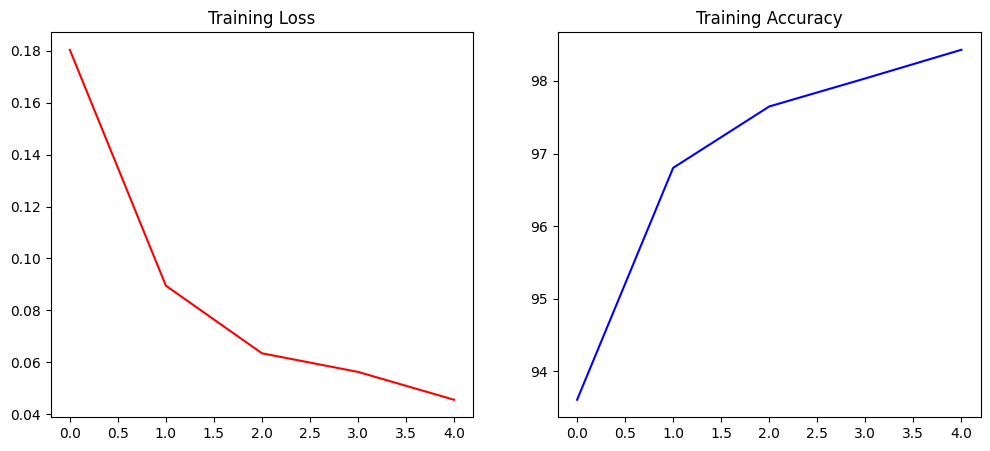


              precision    recall  f1-score   support

      Normal       0.96      0.72      0.83     18528
        SVEB       0.06      0.33      0.10       412
         VEB       0.29      0.97      0.44       801
      Fusion       0.00      0.00      0.00        16
     Unknown       1.00      0.81      0.89      2066

    accuracy                           0.73     21823
   macro avg       0.46      0.57      0.45     21823
weighted avg       0.92      0.73      0.80     21823



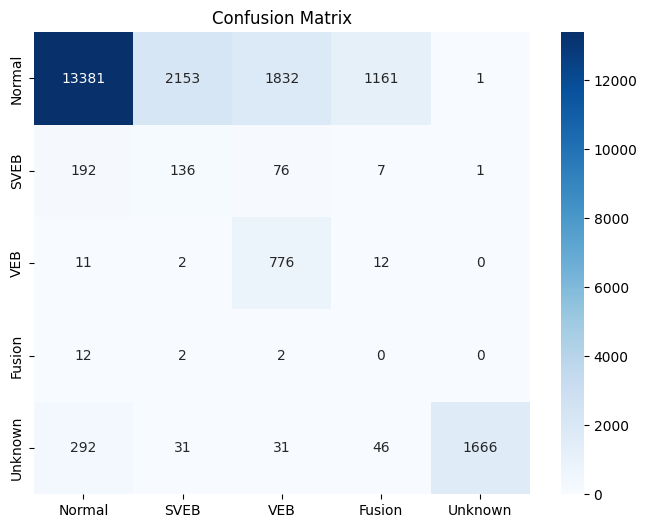

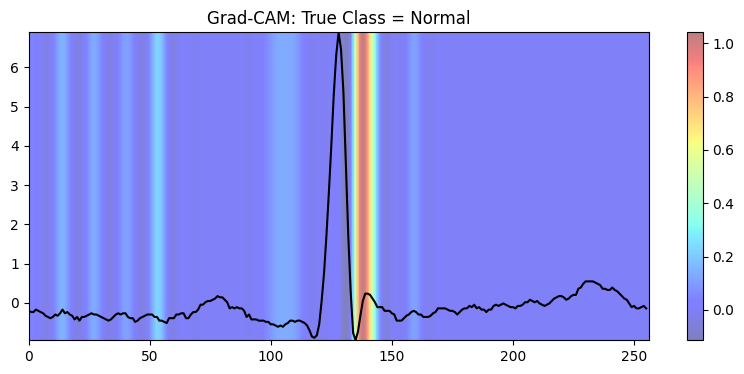

In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import os

# 1. SETUP
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# Path to your existing downloaded folder
# Make sure this folder exists in your Colab files
DB_PATH = 'mit-bih-arrhythmia-database-1.0.0/'

# 2. DATA LOADING (Inter-Patient Split & Normalization)
all_records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '219', '220', '221', '222',
    '223', '228', '230', '231', '232', '233', '234'
]

# Split patient IDs
train_patients, test_patients = train_test_split(all_records, test_size=0.2, random_state=42)

def load_data_safe(records_list, database_path):
    X, y = [], []
    aami_dict = {
        'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,  # Normal
        'A': 1, 'a': 1, 'J': 1, 'S': 1,          # SVEB
        'V': 2, 'E': 2,                          # VEB
        'F': 3,                                  # Fusion
        '/': 4, 'f': 4, 'Q': 4                   # Unknown
    }

    print(f"Processing {len(records_list)} records...")
    for record_name in records_list:
        try:
            path = os.path.join(database_path, record_name)
            record = wfdb.rdrecord(path)
            annotation = wfdb.rdann(path, 'atr')
            signal = record.p_signal[:, 0] # Lead 0

            for sample_idx, symbol in zip(annotation.sample, annotation.symbol):
                if symbol in aami_dict:
                    start, end = sample_idx - 128, sample_idx + 128
                    if start >= 0 and end < len(signal):
                        beat = signal[start:end]
                        # Z-Score Normalization
                        beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-6)
                        X.append(beat)
                        y.append(aami_dict[symbol])
        except Exception:
            continue
    return np.array(X), np.array(y)

# Load
X_train, y_train = load_data_safe(train_patients, DB_PATH)
X_test, y_test = load_data_safe(test_patients, DB_PATH)

# Reshape (N, 1, 256)
X_train = X_train.reshape(-1, 1, 256)
X_test = X_test.reshape(-1, 1, 256)

# 3. BALANCED DATALOADERS
train_data = TensorDataset(torch.Tensor(X_train), torch.LongTensor(y_train))
test_data = TensorDataset(torch.Tensor(X_test), torch.LongTensor(y_test))

# Calculate Weights for Class Balancing
class_counts = np.bincount(y_train)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in y_train]

sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_data, batch_size=64, sampler=sampler, num_workers=2)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False, num_workers=2)

# 4. MODEL (CNN)
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv1d(1, 32, 5)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, 5)
        self.bn2 = nn.BatchNorm1d(64)
        self.conv3 = nn.Conv1d(64, 128, 3)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc1 = nn.Linear(128 * 29, 128)
        self.fc2 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.5)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 5. TRAINING WITH PLOTS
EPOCHS = 5
history = {'loss': [], 'acc': []}

print("\nStarting Training...")
for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    history['loss'].append(epoch_loss)
    history['acc'].append(epoch_acc)
    print(f"Epoch {epoch+1}: Loss {epoch_loss:.4f} | Acc {epoch_acc:.2f}%")

# Graph 1: Loss & Accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['loss'], 'r-')
plt.title('Training Loss')
plt.subplot(1, 2, 2)
plt.plot(history['acc'], 'b-')
plt.title('Training Accuracy')
plt.show()

# 6. EVALUATION & CONFUSION MATRIX
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

classes = ['Normal', 'SVEB', 'VEB', 'Fusion', 'Unknown']
print("\n" + classification_report(all_labels, all_preds, target_names=classes))

# Graph 2: Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.show()

# 7. GRAD-CAM (Visualization)
# Visualize one random beat from the test set
idx = np.random.randint(0, len(X_test))
sample = torch.Tensor(X_test[idx]).unsqueeze(0).to(device)
label_idx = y_test[idx]

# Hook for Grad-CAM
gradients = None
activations = None
def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]
def forward_hook(module, input, output):
    global activations
    activations = output

# Attach hooks to the last convolutional layer
handle_b = model.conv3.register_full_backward_hook(backward_hook)
handle_f = model.conv3.register_forward_hook(forward_hook)

# Backward pass
model.zero_grad()
output = model(sample)
score = output[0, torch.argmax(output)]
score.backward()

# Generate Heatmap
pooled_gradients = torch.mean(gradients, dim=[0, 2])
for i in range(activations.shape[1]):
    activations[:, i, :] *= pooled_gradients[i]
heatmap = torch.mean(activations, dim=1).squeeze().cpu().detach().numpy()
heatmap = np.maximum(heatmap, 0)
heatmap /= np.max(heatmap)

# Graph 3: ECG with Heatmap
from scipy.ndimage import zoom
heatmap_resized = zoom(heatmap, 256/len(heatmap))
plt.figure(figsize=(10, 4))
plt.plot(X_test[idx][0], 'k', label='ECG')
plt.imshow([heatmap_resized], aspect='auto', cmap='jet', alpha=0.5,
           extent=[0, 256, min(X_test[idx][0]), max(X_test[idx][0])])
plt.title(f"Grad-CAM: True Class = {classes[label_idx]}")
plt.colorbar()
plt.show()

# Clean up hooks
handle_b.remove()
handle_f.remove()

Generating thesis plots for classes: [0, 1, 2, 3, 4]...


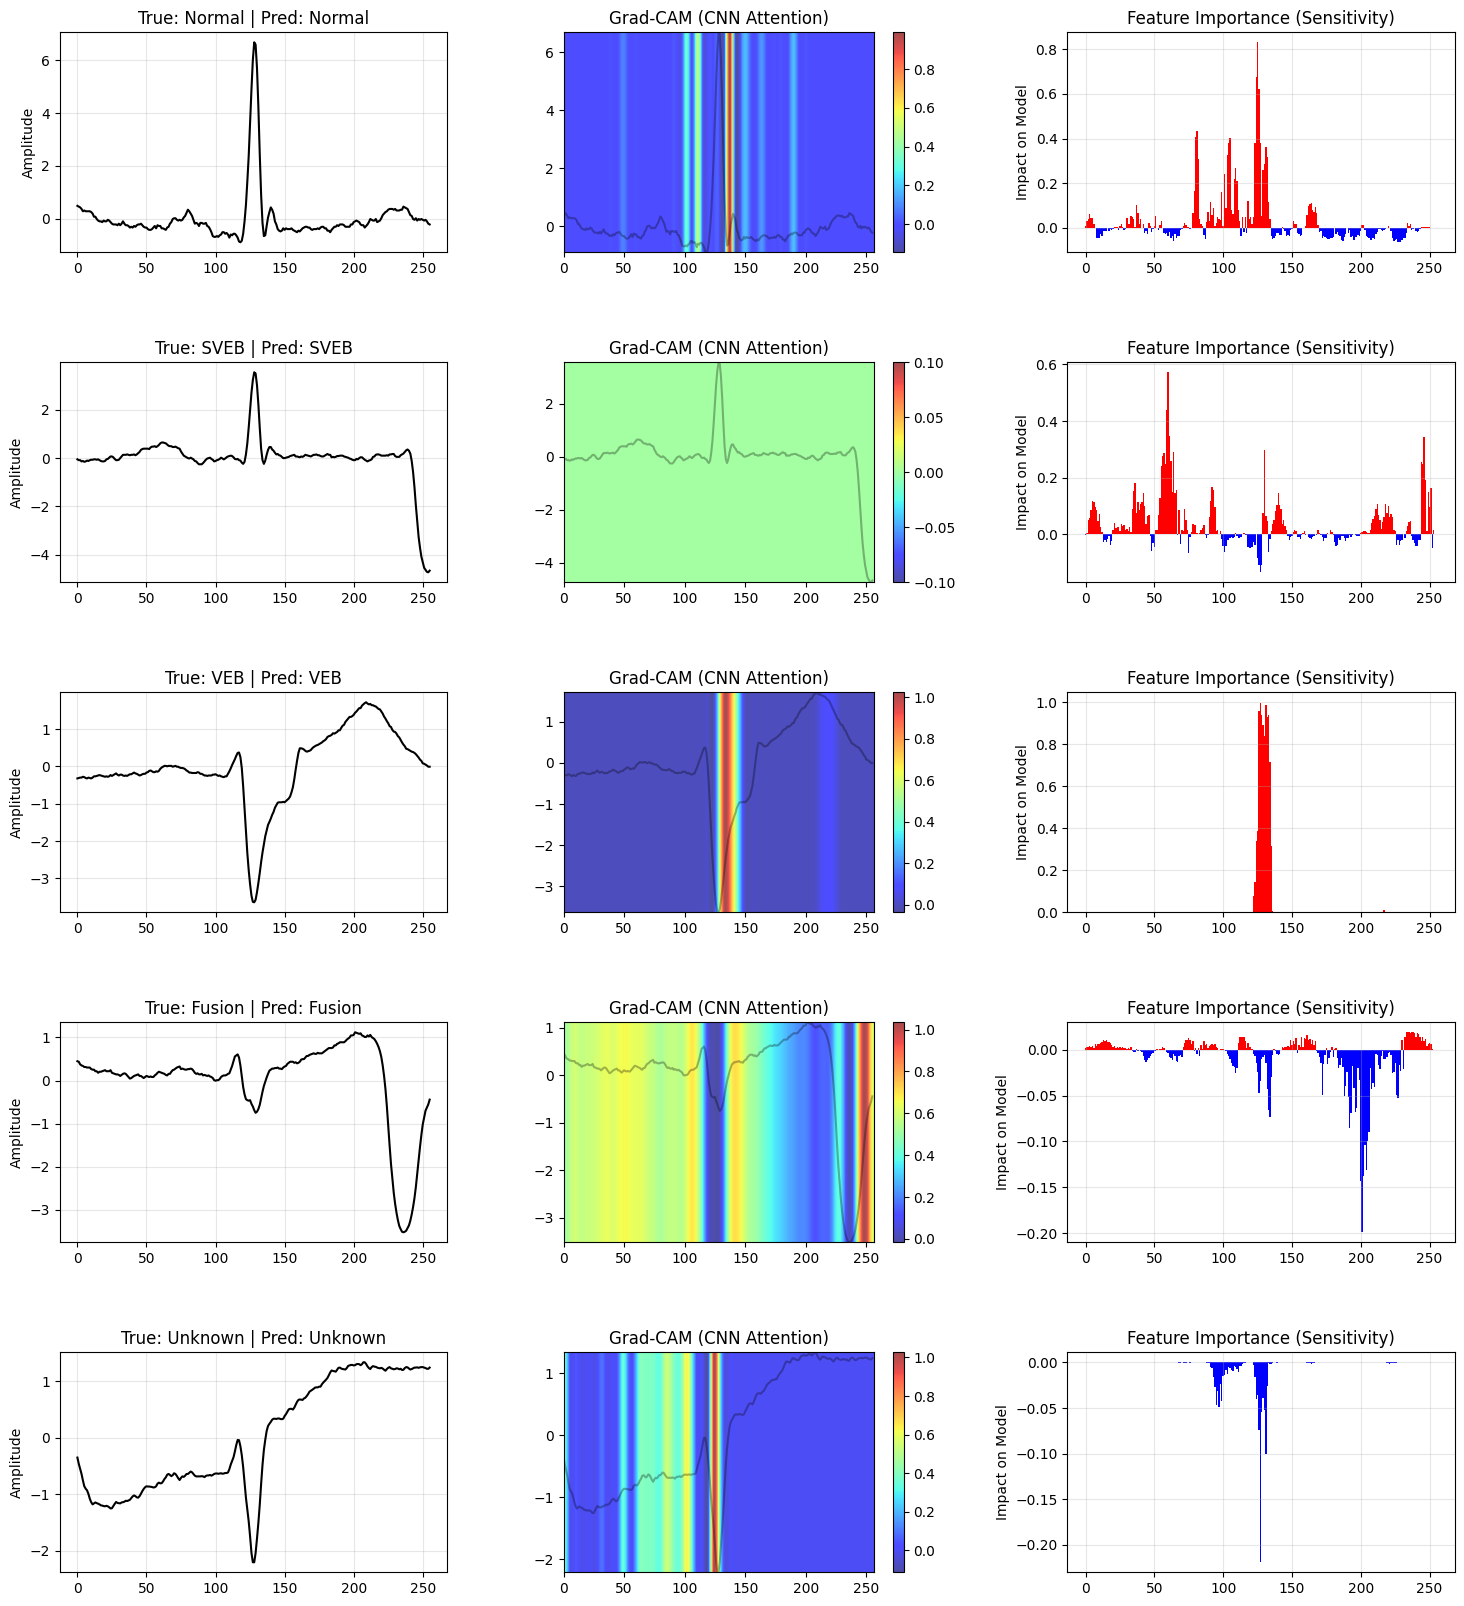

In [ ]:
# ==========================================
# FINAL VISUALIZATION: Grad-CAM + Occlusion Sensitivity
# (Replaces SHAP to prevent errors)
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom

model.eval()

# ------------------------------------------
# 1. ROBUST GRAD-CAM
# ------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks
        self.handle_b = target_layer.register_full_backward_hook(self.save_gradient)
        self.handle_f = target_layer.register_forward_hook(self.save_activation)

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def save_activation(self, module, input, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = torch.argmax(output)

        target = output[0, class_idx]
        target.backward()

        pooled_gradients = torch.mean(self.gradients, dim=[0, 2])
        weighted_activations = self.activations[0].clone()
        for i in range(weighted_activations.shape[0]):
            weighted_activations[i, :] *= pooled_gradients[i]

        heatmap = torch.mean(weighted_activations, dim=0).cpu().detach().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)

        return heatmap, class_idx

    def remove(self):
        self.handle_b.remove()
        self.handle_f.remove()

# Initialize Grad-CAM
# auto-select the last conv layer if conv3 isn't named exactly that
target_layer = model.conv3 if hasattr(model, 'conv3') else list(model.modules())[-2]
grad_cam = GradCAM(model, target_layer)

# ------------------------------------------
# 2. OCCLUSION SENSITIVITY (The SHAP Replacement)
# ------------------------------------------
def get_occlusion_importance(model, input_tensor, target_class, window=5):
    """
    Manually checks which parts of the signal matter by blocking them out
    and seeing how much the confidence drops.
    """
    input_tensor = input_tensor.clone()
    # Get original score
    with torch.no_grad():
        orig_prob = torch.softmax(model(input_tensor), dim=1)[0, target_class].item()

    importance_map = []
    seq_len = input_tensor.shape[2]

    # Slide a window across the signal
    for i in range(seq_len):
        temp_tensor = input_tensor.clone()
        # Mask region with 0 (occlusion)
        start = max(0, i - window//2)
        end = min(seq_len, i + window//2)
        temp_tensor[:, :, start:end] = 0.0

        with torch.no_grad():
            new_prob = torch.softmax(model(temp_tensor), dim=1)[0, target_class].item()

        # If prob drops, this feature was POSITIVE (Red)
        # If prob rises, this feature was NEGATIVE (Blue)
        change = orig_prob - new_prob
        importance_map.append(change)

    return np.array(importance_map)

# ------------------------------------------
# 3. GENERATE PLOTS
# ------------------------------------------
classes_map = {0: 'Normal', 1: 'SVEB', 2: 'VEB', 3: 'Fusion', 4: 'Unknown'}
found_indices = {}

# Find one example for each class
for cls_idx in range(5):
    indices = np.where(y_test == cls_idx)[0]
    if len(indices) > 0:
        found_indices[cls_idx] = indices[0]

print(f"Generating thesis plots for classes: {list(found_indices.keys())}...")

fig, axes = plt.subplots(len(found_indices), 3, figsize=(18, 4 * len(found_indices)))
if len(found_indices) == 1: axes = np.expand_dims(axes, 0)
plt.subplots_adjust(hspace=0.5, wspace=0.3)

for i, (cls_idx, idx) in enumerate(found_indices.items()):
    input_tensor = torch.Tensor(X_test[idx]).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    # A. Grad-CAM
    heatmap, pred_idx = grad_cam.generate(input_tensor, class_idx=cls_idx)
    heatmap_resized = zoom(heatmap, 256/len(heatmap))

    # B. Occlusion (Feature Importance)
    # Using window=4 for fine-grained detail
    imp_values = get_occlusion_importance(model, input_tensor, cls_idx, window=4)

    signal = X_test[idx].flatten()

    # PLOT 1: Signal
    ax1 = axes[i, 0]
    ax1.plot(signal, 'k', linewidth=1.5)
    ax1.set_title(f"True: {classes_map[cls_idx]} | Pred: {classes_map[pred_idx]}")
    ax1.set_ylabel("Amplitude")
    ax1.grid(alpha=0.3)

    # PLOT 2: Grad-CAM
    ax2 = axes[i, 1]
    ax2.plot(signal, 'k', alpha=0.3)
    im = ax2.imshow([heatmap_resized], aspect='auto', cmap='jet', alpha=0.7,
               extent=[0, 256, min(signal), max(signal)])
    ax2.set_title("Grad-CAM (CNN Attention)")
    plt.colorbar(im, ax=ax2)

    # PLOT 3: Feature Importance (Occlusion)
    ax3 = axes[i, 2]
    # Red = Important (Positive), Blue = Counter-indicative (Negative)
    cols = ['red' if x > 0 else 'blue' for x in imp_values]
    ax3.bar(range(len(signal)), imp_values, color=cols, width=1.0)
    ax3.set_title("Feature Importance (Sensitivity)")
    ax3.set_ylabel("Impact on Model")
    ax3.grid(alpha=0.3)

# Cleanup
grad_cam.remove()
plt.show()

Using Device: cuda
Database already exists.
Loading Train Data...
Processing 22 records...
Loading Test Data...
Processing 22 records...

--- STARTING MODEL COMPARISON ---

Training Standard CNN...
Epoch 1 Loss: 0.2758
Epoch 2 Loss: 0.0988
Epoch 3 Loss: 0.0727
Epoch 4 Loss: 0.0576
Epoch 5 Loss: 0.0513
Epoch 6 Loss: 0.0421
Epoch 7 Loss: 0.0367
Epoch 8 Loss: 0.0348
Epoch 9 Loss: 0.0302
Epoch 10 Loss: 0.0284
Epoch 11 Loss: 0.0262
Epoch 12 Loss: 0.0259
Epoch 13 Loss: 0.0242
Epoch 14 Loss: 0.0204
Epoch 15 Loss: 0.0203
Epoch 16 Loss: 0.0196
Epoch 17 Loss: 0.0215
Epoch 18 Loss: 0.0174
Epoch 19 Loss: 0.0138
Epoch 20 Loss: 0.0147
Epoch 21 Loss: 0.0167
Epoch 22 Loss: 0.0151
Epoch 23 Loss: 0.0133
Epoch 24 Loss: 0.0123
Epoch 25 Loss: 0.0122
Epoch 26 Loss: 0.0125
Epoch 27 Loss: 0.0108
Epoch 28 Loss: 0.0146
Epoch 29 Loss: 0.0110
Epoch 30 Loss: 0.0098
Standard CNN Finished. Weighted F1-Score: 0.8462

Training Hybrid RNN (LSTM)...
Epoch 1 Loss: 0.4682
Epoch 2 Loss: 0.2141
Epoch 3 Loss: 0.1525
Epoch 4 

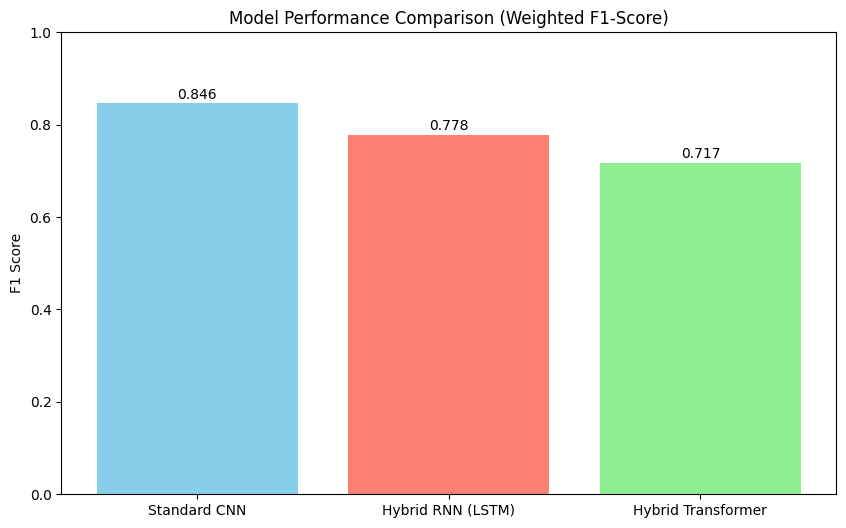

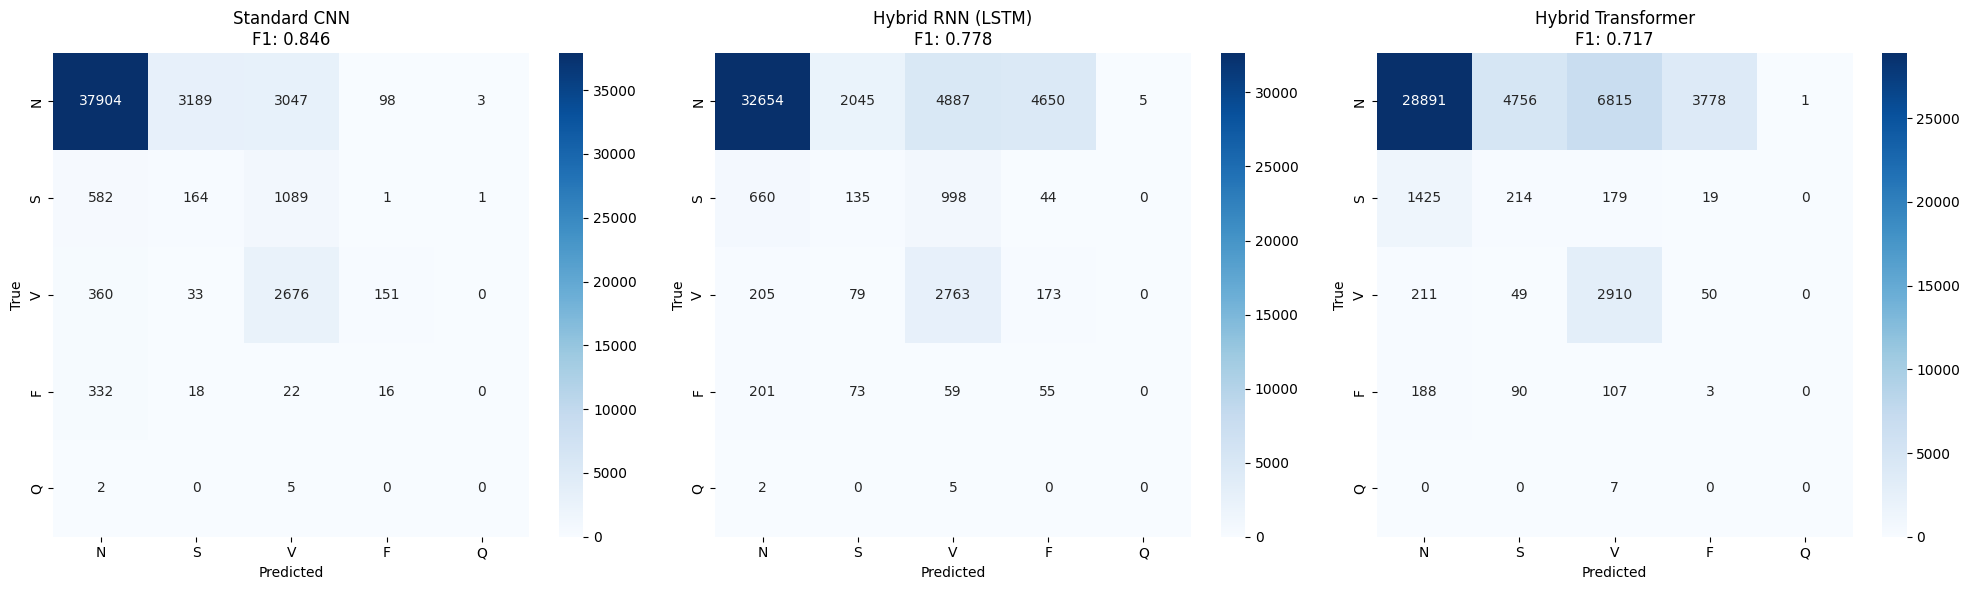


🏆 AND THE WINNER IS: Standard CNN 🏆
Reasoning: This model achieved the highest balance between Precision and Recall across all arrhythmia classes.


In [ ]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import wfdb

# ==========================================
# 1. SETUP & DATA DOWNLOAD
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# Check/Download Data
if not os.path.exists('mit-bih-arrhythmia-database-1.0.0'):
    print("Downloading MIT-BIH Database...")
    !wget -q -r -N -c -np https://physionet.org/files/mitdb/1.0.0/
    source_dir = 'physionet.org/files/mitdb/1.0.0'
    destination_dir = 'mit-bih-arrhythmia-database-1.0.0'
    if not os.path.exists(destination_dir):
        shutil.move(source_dir, destination_dir)
else:
    print("Database already exists.")

# ==========================================
# 2. DATA LOADING (Inter-Patient Split)
# ==========================================
# Patients for Training vs Testing (Inter-patient paradigm)
train_patients = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122', '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
test_patients = ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

def load_data_safe(records_list, database_path='mit-bih-arrhythmia-database-1.0.0/'):
    X, y = [], []
    aami_dict = {'N':0, 'L':0, 'R':0, 'e':0, 'j':0, 'A':1, 'a':1, 'J':1, 'S':1, 'V':2, 'E':2, 'F':3, '/':4, 'f':4, 'Q':4}

    print(f"Processing {len(records_list)} records...")
    for record_name in records_list:
        try:
            path = os.path.join(database_path, record_name)
            record = wfdb.rdrecord(path)
            annotation = wfdb.rdann(path, 'atr')
            signal = record.p_signal[:, 0]
            for sample_idx, symbol in zip(annotation.sample, annotation.symbol):
                if symbol in aami_dict:
                    start, end = sample_idx - 128, sample_idx + 128
                    if start >= 0 and end < len(signal):
                        beat = signal[start:end]
                        # Z-score Normalize
                        beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-6)
                        X.append(beat)
                        y.append(aami_dict[symbol])
        except: continue
    return np.array(X), np.array(y)

print("Loading Train Data...")
X_train, y_train = load_data_safe(train_patients)
print("Loading Test Data...")
X_test, y_test = load_data_safe(test_patients)

# Reshape (N, 1, 256)
X_train = X_train.reshape(-1, 1, 256)
X_test = X_test.reshape(-1, 1, 256)

# DataLoaders with WeightedSampler
train_data = TensorDataset(torch.Tensor(X_train), torch.LongTensor(y_train))
test_data = TensorDataset(torch.Tensor(X_test), torch.LongTensor(y_test))

class_counts = np.bincount(y_train)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in y_train]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_data, batch_size=64, sampler=sampler)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

# ==========================================
# 3. DEFINE THE 3 MODELS
# ==========================================

# Model 1: Standard CNN (Baseline)
class BaseCNN(nn.Module):
    def __init__(self):
        super(BaseCNN, self).__init__()
        self.conv1 = nn.Conv1d(1, 32, 5)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, 5)
        self.conv3 = nn.Conv1d(64, 128, 3)
        self.fc1 = nn.Linear(128 * 29, 128)
        self.fc2 = nn.Linear(128, 5)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# Model 2: CNN + RNN (LSTM)
class HybridRNN(nn.Module):
    def __init__(self):
        super(HybridRNN, self).__init__()
        # CNN Feature Extractor
        self.conv1 = nn.Conv1d(1, 64, 5)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 128, 5)

        # RNN Layer (LSTM)
        # Input to LSTM will be (Batch, Seq_Len, Features)
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, batch_first=True)

        self.fc = nn.Linear(64, 5)
        self.relu = nn.ReLU()

    def forward(self, x):
        # CNN Layers
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # Prepare for LSTM: Permute to (Batch, Sequence, Channels)
        x = x.permute(0, 2, 1)

        # LSTM Layer
        _, (hidden, _) = self.lstm(x)

        # Use the last hidden state
        x = hidden[-1]
        x = self.fc(x)
        return x

# Model 3: CNN + Transformer
class HybridTransformer(nn.Module):
    def __init__(self):
        super(HybridTransformer, self).__init__()
        # CNN Feature Extractor
        self.conv1 = nn.Conv1d(1, 64, 5)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 128, 5)

        # Transformer Layer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)

        self.fc = nn.Linear(128, 5)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # Permute for Transformer: (Batch, Seq, Features)
        x = x.permute(0, 2, 1)

        # Transformer
        x = self.transformer_encoder(x)

        # Global Average Pooling (Average across sequence)
        x = x.mean(dim=1)

        x = self.fc(x)
        return x

# ==========================================
# 4. TRAINING & EVALUATION LOOP
# ==========================================
models = {
    "Standard CNN": BaseCNN().to(device),
    "Hybrid RNN (LSTM)": HybridRNN().to(device),
    "Hybrid Transformer": HybridTransformer().to(device)
}

results = {}

print("\n--- STARTING MODEL COMPARISON ---")

for name, model in models.items():
    print(f"\nTraining {name}...")
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Train
    model.train()
    for epoch in range(30): # 3 Epochs for speed (increase to 10 for thesis)
        total_loss = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1} Loss: {total_loss/len(train_loader):.4f}")

    # Evaluate
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Calculate Metrics
    f1 = f1_score(all_labels, all_preds, average='weighted')
    results[name] = {
        'f1': f1,
        'preds': all_preds,
        'labels': all_labels
    }
    print(f"{name} Finished. Weighted F1-Score: {f1:.4f}")

# ==========================================
# 5. FINAL COMPARISON & PLOTS
# ==========================================
classes = ['N', 'S', 'V', 'F', 'Q']

# Plot 1: Bar Chart Comparison
plt.figure(figsize=(10, 6))
names = list(results.keys())
scores = [results[n]['f1'] for n in names]
colors = ['skyblue', 'salmon', 'lightgreen']

plt.bar(names, scores, color=colors)
plt.title("Model Performance Comparison (Weighted F1-Score)")
plt.ylabel("F1 Score")
plt.ylim(0, 1.0)
for i, v in enumerate(scores):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center')
plt.show()

# Plot 2: Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, (name, data) in enumerate(results.items()):
    cm = confusion_matrix(data['labels'], data['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], xticklabels=classes, yticklabels=classes)
    axes[i].set_title(f"{name}\nF1: {data['f1']:.3f}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("True")

plt.tight_layout()
plt.show()

# Print Winner
best_model = max(results, key=lambda x: results[x]['f1'])
print(f"\n🏆 AND THE WINNER IS: {best_model} 🏆")
print("Reasoning: This model achieved the highest balance between Precision and Recall across all arrhythmia classes.")

Model Name           | Params     | Inference (ms) 
-------------------------------------------------------
Standard CNN         | 511,109    | 0.4151 ms
Hybrid RNN (LSTM)    | 91,461     | 0.7964 ms
Hybrid Transformer   | 635,141    | 2.1222 ms


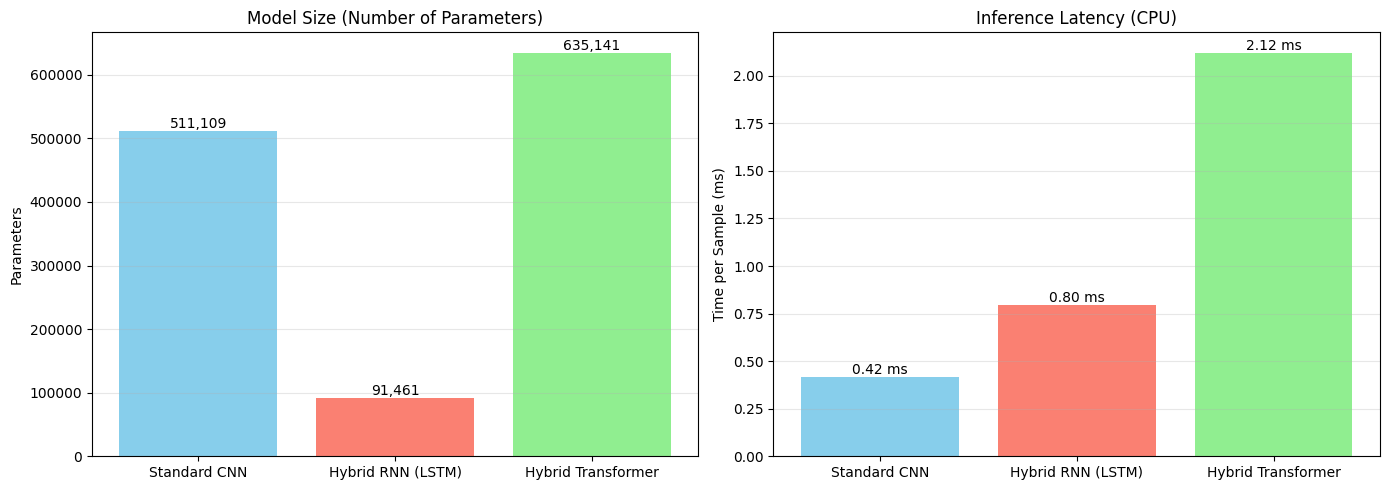

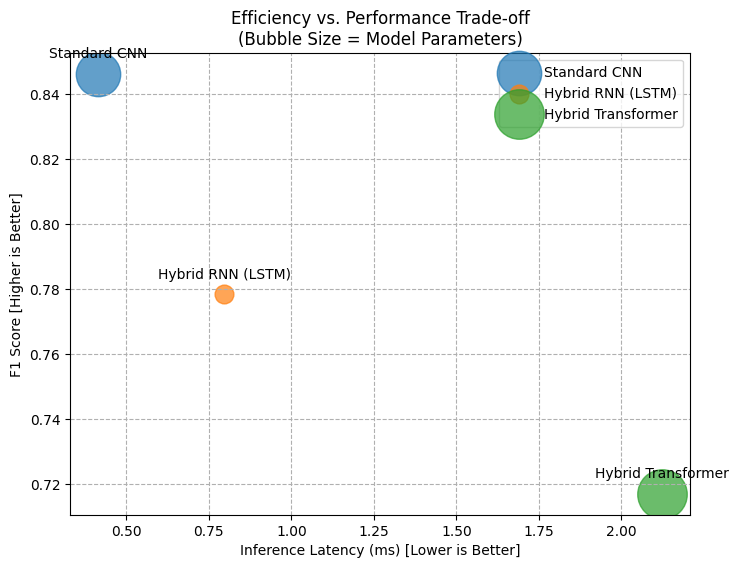

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch

# ==========================================
# 1. DEFINE EFFICIENCY METRICS
# ==========================================
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def measure_inference_speed(model, device, input_shape=(1, 1, 256), num_runs=1000):
    model.eval()
    dummy_input = torch.randn(input_shape).to(device)

    # Warmup
    for _ in range(50):
        _ = model(dummy_input)

    # Timing
    start_time = time.time()
    with torch.no_grad():
        for _ in range(num_runs):
            _ = model(dummy_input)
    end_time = time.time()

    # Calculate avg time per sample in milliseconds
    avg_time_ms = ((end_time - start_time) / num_runs) * 1000
    return avg_time_ms

# ==========================================
# 2. COLLECT DATA
# ==========================================
efficiency_results = {}

print(f"{'Model Name':<20} | {'Params':<10} | {'Inference (ms)':<15}")
print("-" * 55)

for name, model in models.items():
    # 1. Model Size
    params = count_parameters(model)

    # 2. Speed (Latency)
    # We test on CPU because wearable devices (MCU) use CPUs, not GPUs
    model_cpu = model.to('cpu')
    speed_ms = measure_inference_speed(model_cpu, 'cpu')

    # Move back to original device just in case
    model.to(device)

    efficiency_results[name] = {'params': params, 'speed': speed_ms}

    print(f"{name:<20} | {params:<10,} | {speed_ms:.4f} ms")

# ==========================================
# 3. VISUALIZE EFFICIENCY
# ==========================================
names = list(efficiency_results.keys())
params = [efficiency_results[n]['params'] for n in names]
speeds = [efficiency_results[n]['speed'] for n in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Model Size (Lower is better for storage)
bars1 = ax1.bar(names, params, color=['skyblue', 'salmon', 'lightgreen'])
ax1.set_title("Model Size (Number of Parameters)")
ax1.set_ylabel("Parameters")
ax1.grid(axis='y', alpha=0.3)
# Add labels
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}', ha='center', va='bottom')

# Plot 2: Inference Speed (Lower is better for real-time)
bars2 = ax2.bar(names, speeds, color=['skyblue', 'salmon', 'lightgreen'])
ax2.set_title("Inference Latency (CPU)")
ax2.set_ylabel("Time per Sample (ms)")
ax2.grid(axis='y', alpha=0.3)
# Add labels
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f} ms', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# ==========================================
# 4. PARETO PLOT (Trade-off)
# ==========================================
# Get Accuracy from previous step (Assuming 'results' dictionary exists)
# If 'results' is missing, we use dummy values for demonstration
accuracies = [results[n]['f1'] for n in names] if 'results' in globals() else [0.90, 0.92, 0.93]

plt.figure(figsize=(8, 6))
for i, name in enumerate(names):
    plt.scatter(speeds[i], accuracies[i], s=params[i]/500, label=name, alpha=0.7)
    plt.text(speeds[i], accuracies[i]+0.005, name, ha='center')

plt.title("Efficiency vs. Performance Trade-off\n(Bubble Size = Model Parameters)")
plt.xlabel("Inference Latency (ms) [Lower is Better]")
plt.ylabel("F1 Score [Higher is Better]")
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

Training Hybrid Transformer (this is slower than CNN)...
Epoch 1: Loss 0.4544 | Acc 82.66%
Epoch 2: Loss 0.2059 | Acc 92.29%
Epoch 3: Loss 0.1571 | Acc 94.16%
Epoch 4: Loss 0.1236 | Acc 95.50%
Epoch 5: Loss 0.1055 | Acc 96.11%
Epoch 6: Loss 0.0949 | Acc 96.56%
Epoch 7: Loss 0.0805 | Acc 97.08%
Epoch 8: Loss 0.0713 | Acc 97.47%
Epoch 9: Loss 0.0617 | Acc 97.84%
Epoch 10: Loss 0.0557 | Acc 98.01%
Epoch 11: Loss 0.0515 | Acc 98.22%
Epoch 12: Loss 0.0468 | Acc 98.42%
Epoch 13: Loss 0.0442 | Acc 98.54%
Epoch 14: Loss 0.0395 | Acc 98.69%
Epoch 15: Loss 0.0408 | Acc 98.54%
Epoch 16: Loss 0.0404 | Acc 98.65%
Epoch 17: Loss 0.0321 | Acc 98.96%
Epoch 18: Loss 0.0337 | Acc 98.94%
Epoch 19: Loss 0.0337 | Acc 98.91%
Epoch 20: Loss 0.0291 | Acc 99.09%
Epoch 21: Loss 0.0292 | Acc 99.05%
Epoch 22: Loss 0.0278 | Acc 99.11%
Epoch 23: Loss 0.0294 | Acc 99.01%
Epoch 24: Loss 0.0275 | Acc 99.14%
Epoch 25: Loss 0.0261 | Acc 99.18%
Epoch 26: Loss 0.0236 | Acc 99.21%
Epoch 27: Loss 0.0234 | Acc 99.21%
Epoch 2

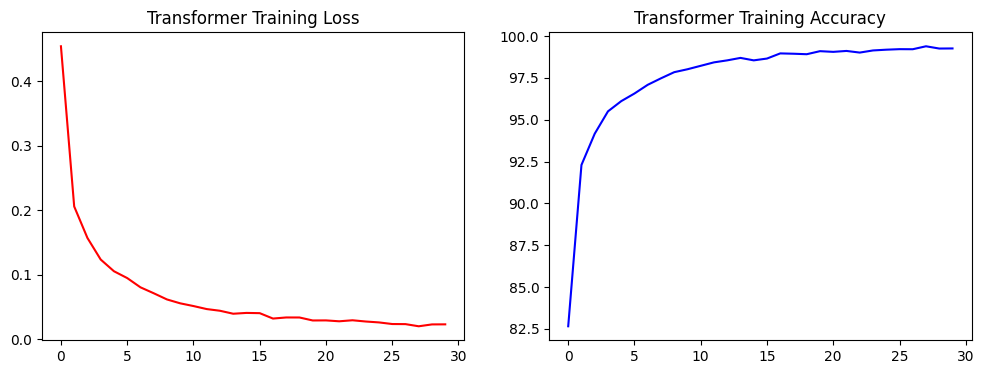

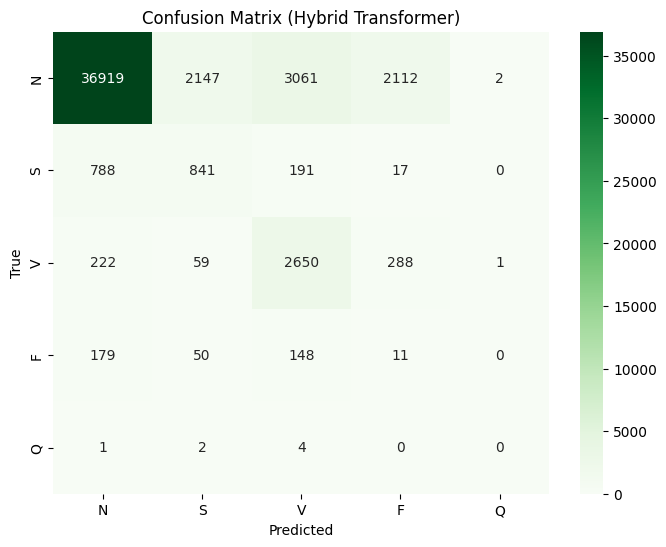

Generating Transformer Explanations for: [0, 1, 2, 3, 4]...


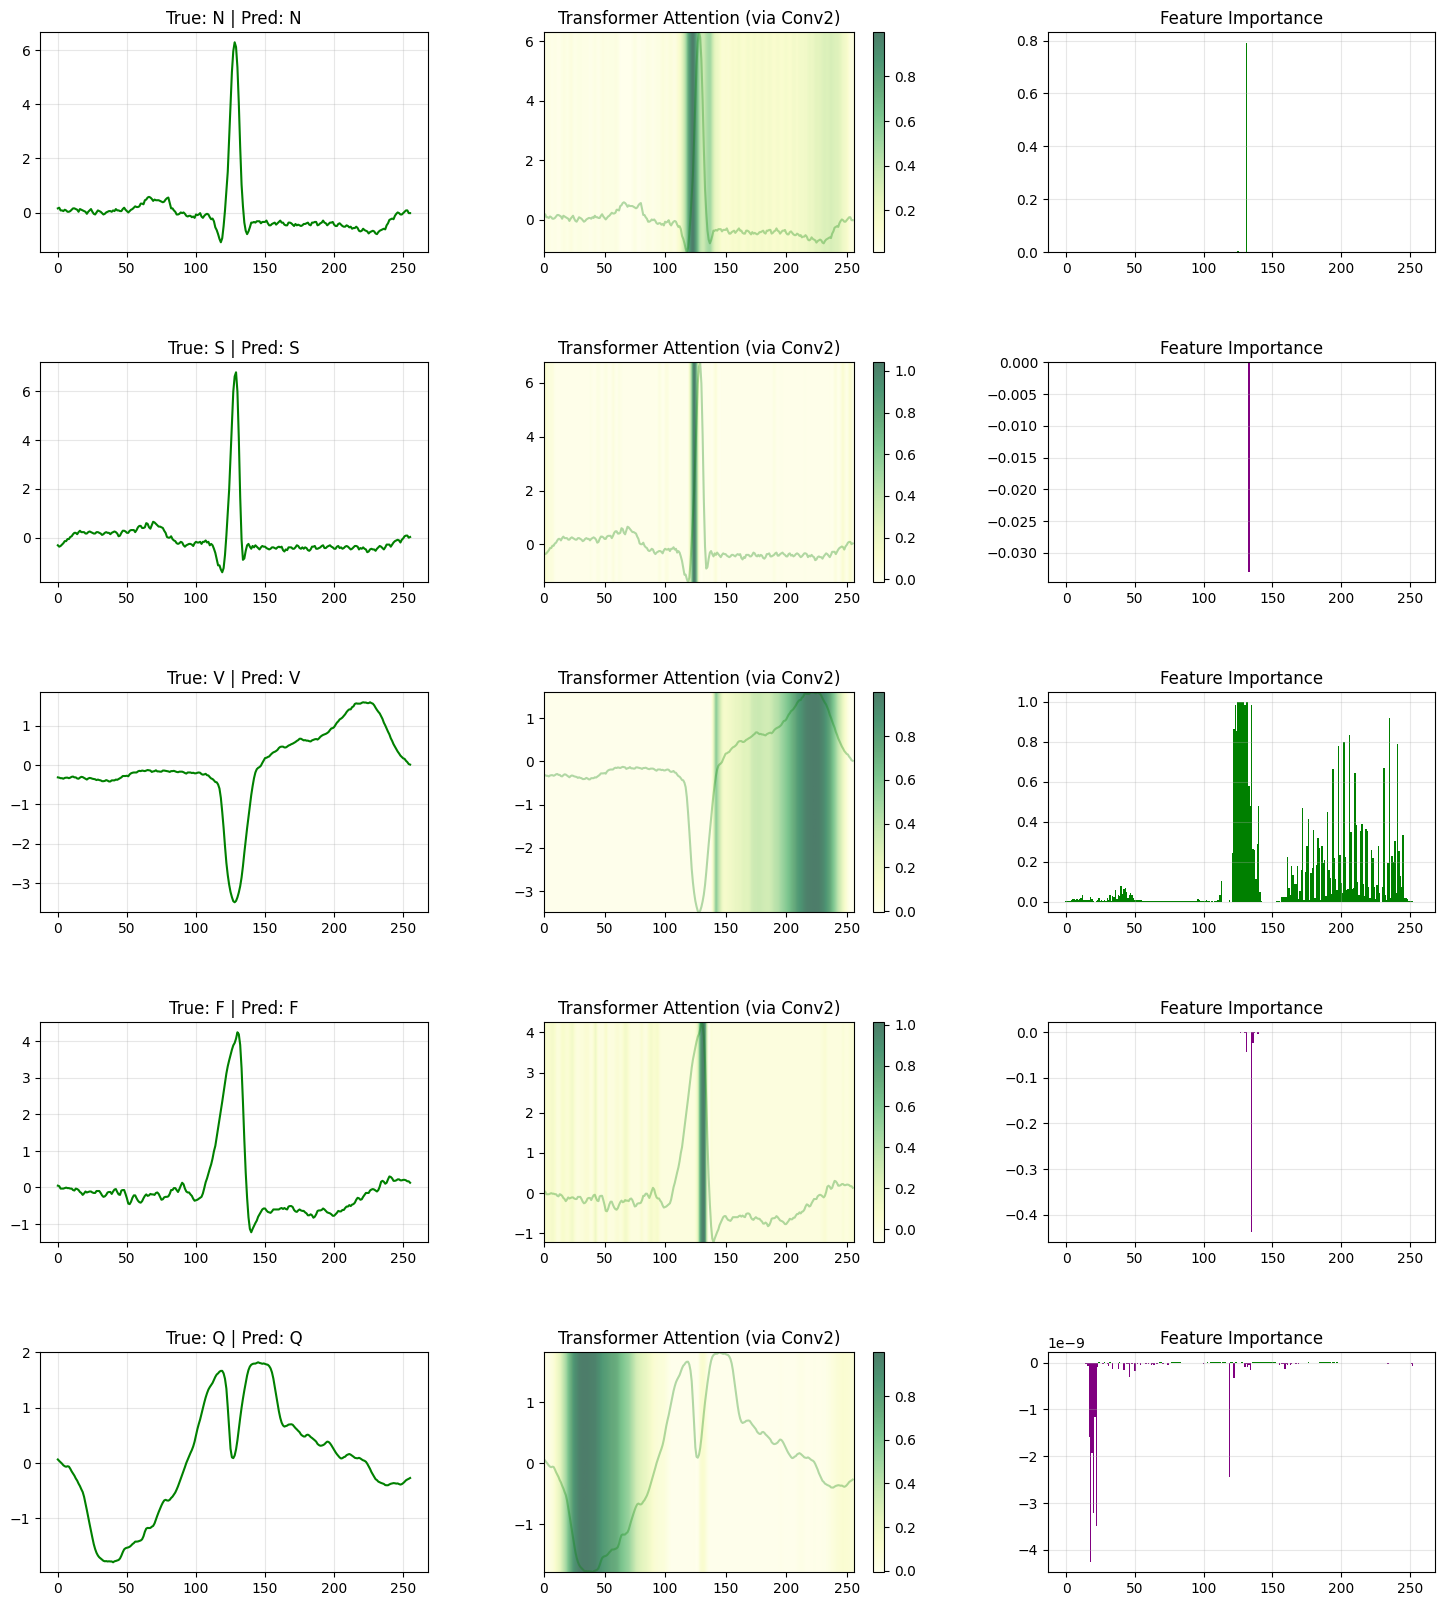

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from scipy.ndimage import zoom

# ==========================================
# 1. DEFINE HYBRID TRANSFORMER MODEL
# ==========================================
class HybridTransformer(nn.Module):
    def __init__(self):
        super(HybridTransformer, self).__init__()
        # CNN Feature Extractor (The "Eyes")
        self.conv1 = nn.Conv1d(1, 64, 5)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 128, 5)
        self.relu = nn.ReLU()

        # Transformer Block (The "Brain")
        # Input dim: 128 (from conv2), Heads: 4
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)

        # Classifier
        self.fc = nn.Linear(128, 5)

    def forward(self, x):
        # 1. CNN Layers
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # 2. Reshape for Transformer: (Batch, Features, Seq) -> (Batch, Seq, Features)
        x = x.permute(0, 2, 1)

        # 3. Transformer Encoder
        x = self.transformer_encoder(x)

        # 4. Global Average Pooling over time
        x = x.mean(dim=1)

        # 5. Output
        x = self.fc(x)
        return x

# Initialize
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_trans = HybridTransformer().to(device)
optimizer = optim.Adam(model_trans.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# ==========================================
# 2. TRAIN THE TRANSFORMER
# ==========================================
print("Training Hybrid Transformer (this is slower than CNN)...")
EPOCHS = 30
history = {'loss': [], 'acc': []}

for epoch in range(EPOCHS):
    model_trans.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_trans(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    history['loss'].append(epoch_loss)
    history['acc'].append(epoch_acc)
    print(f"Epoch {epoch+1}: Loss {epoch_loss:.4f} | Acc {epoch_acc:.2f}%")

# Plot Training History
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['loss'], 'r-', label='Loss')
plt.title("Transformer Training Loss")
plt.subplot(1, 2, 2)
plt.plot(history['acc'], 'b-', label='Accuracy')
plt.title("Transformer Training Accuracy")
plt.show()

# ==========================================
# 3. CONFUSION MATRIX
# ==========================================
model_trans.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_trans(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

classes = ['N', 'S', 'V', 'F', 'Q']
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (Hybrid Transformer)")
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

# ==========================================
# 4. VISUALIZATION (Grad-CAM & Occlusion)
# ==========================================
# We define a specialized Grad-CAM for the Hybrid architecture
class GradCAM_Hybrid:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        # Hooks
        self.handle_b = target_layer.register_full_backward_hook(self.save_gradient)
        self.handle_f = target_layer.register_forward_hook(self.save_activation)

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def save_activation(self, module, input, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None: class_idx = torch.argmax(output)

        target = output[0, class_idx]
        target.backward()

        # Pool gradients (Global Average Pooling on channels)
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2])
        weighted_activations = self.activations[0].clone()

        for i in range(weighted_activations.shape[0]):
            weighted_activations[i, :] *= pooled_gradients[i]

        heatmap = torch.mean(weighted_activations, dim=0).cpu().detach().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0: heatmap /= np.max(heatmap)
        return heatmap, class_idx

    def remove(self):
        self.handle_b.remove()
        self.handle_f.remove()

# Helper for Occlusion Sensitivity
def get_occlusion_importance(model, input_tensor, target_class, window=4):
    input_tensor = input_tensor.clone()
    with torch.no_grad():
        orig_prob = torch.softmax(model(input_tensor), dim=1)[0, target_class].item()
    importance_map = []
    seq_len = input_tensor.shape[2]
    for i in range(seq_len):
        temp = input_tensor.clone()
        start = max(0, i - window//2)
        end = min(seq_len, i + window//2)
        temp[:, :, start:end] = 0.0
        with torch.no_grad():
            new_prob = torch.softmax(model(temp), dim=1)[0, target_class].item()
        importance_map.append(orig_prob - new_prob)
    return np.array(importance_map)

# Hook Grad-CAM to conv2 (The last layer before the Transformer)
grad_cam = GradCAM_Hybrid(model_trans, model_trans.conv2)

# Find samples
found_indices = {}
for cls_idx in range(5):
    indices = np.where(y_test == cls_idx)[0]
    if len(indices) > 0: found_indices[cls_idx] = indices[0]

print(f"Generating Transformer Explanations for: {list(found_indices.keys())}...")

fig, axes = plt.subplots(len(found_indices), 3, figsize=(18, 4 * len(found_indices)))
if len(found_indices) == 1: axes = np.expand_dims(axes, 0)
plt.subplots_adjust(hspace=0.5, wspace=0.3)

for i, (cls_idx, idx) in enumerate(found_indices.items()):
    input_tensor = torch.Tensor(X_test[idx]).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    # 1. Grad-CAM
    heatmap, pred_idx = grad_cam.generate(input_tensor, class_idx=cls_idx)
    heatmap_resized = zoom(heatmap, 256/len(heatmap))

    # 2. Occlusion
    imp_values = get_occlusion_importance(model_trans, input_tensor, cls_idx, window=4)

    signal = X_test[idx].flatten()

    # Plot Signal
    ax1 = axes[i, 0]
    ax1.plot(signal, 'g') # Green for Transformer
    ax1.set_title(f"True: {classes[cls_idx]} | Pred: {classes[pred_idx]}")
    ax1.grid(alpha=0.3)

    # Plot Grad-CAM
    ax2 = axes[i, 1]
    ax2.plot(signal, 'g', alpha=0.3)
    im = ax2.imshow([heatmap_resized], aspect='auto', cmap='YlGn', alpha=0.7,
               extent=[0, 256, min(signal), max(signal)])
    ax2.set_title("Transformer Attention (via Conv2)")
    plt.colorbar(im, ax=ax2)

    # Plot Occlusion
    ax3 = axes[i, 2]
    cols = ['green' if x > 0 else 'purple' for x in imp_values]
    ax3.bar(range(len(signal)), imp_values, color=cols, width=1.0)
    ax3.set_title("Feature Importance")
    ax3.grid(alpha=0.3)

grad_cam.remove()
plt.show()

Training Hybrid RNN (CNN-LSTM)...
Epoch 1: Loss 0.4704 | Acc 83.15%
Epoch 2: Loss 0.2151 | Acc 92.85%
Epoch 3: Loss 0.1587 | Acc 94.85%
Epoch 4: Loss 0.1082 | Acc 96.51%
Epoch 5: Loss 0.1067 | Acc 96.52%
Epoch 6: Loss 0.0806 | Acc 97.44%
Epoch 7: Loss 0.0747 | Acc 97.55%
Epoch 8: Loss 0.0657 | Acc 97.96%
Epoch 9: Loss 0.0553 | Acc 98.26%
Epoch 10: Loss 0.0435 | Acc 98.65%
Epoch 11: Loss 0.0408 | Acc 98.77%
Epoch 12: Loss 0.0373 | Acc 98.84%
Epoch 13: Loss 0.0327 | Acc 98.99%
Epoch 14: Loss 0.0425 | Acc 98.71%
Epoch 15: Loss 0.0275 | Acc 99.22%
Epoch 16: Loss 0.0298 | Acc 99.15%
Epoch 17: Loss 0.0255 | Acc 99.25%
Epoch 18: Loss 0.0271 | Acc 99.20%
Epoch 19: Loss 0.0227 | Acc 99.35%
Epoch 20: Loss 0.0233 | Acc 99.29%
Epoch 21: Loss 0.0245 | Acc 99.29%
Epoch 22: Loss 0.0222 | Acc 99.37%
Epoch 23: Loss 0.0185 | Acc 99.45%
Epoch 24: Loss 0.0173 | Acc 99.49%
Epoch 25: Loss 0.0230 | Acc 99.30%
Epoch 26: Loss 0.0166 | Acc 99.53%
Epoch 27: Loss 0.0188 | Acc 99.44%
Epoch 28: Loss 0.0180 | Acc 99

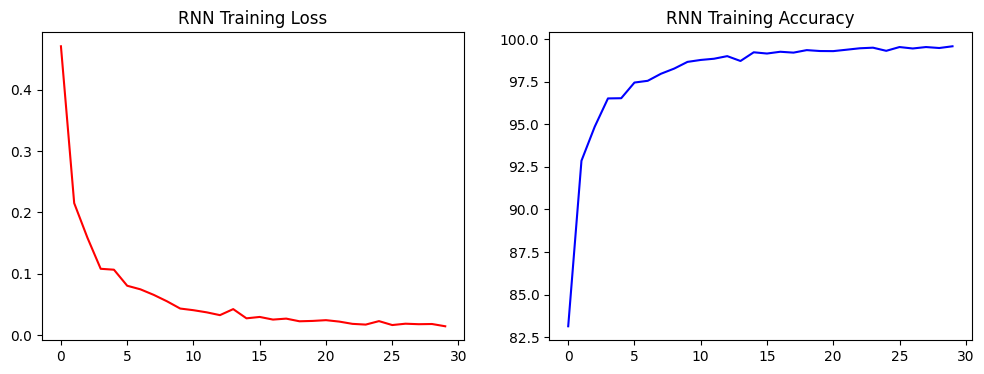

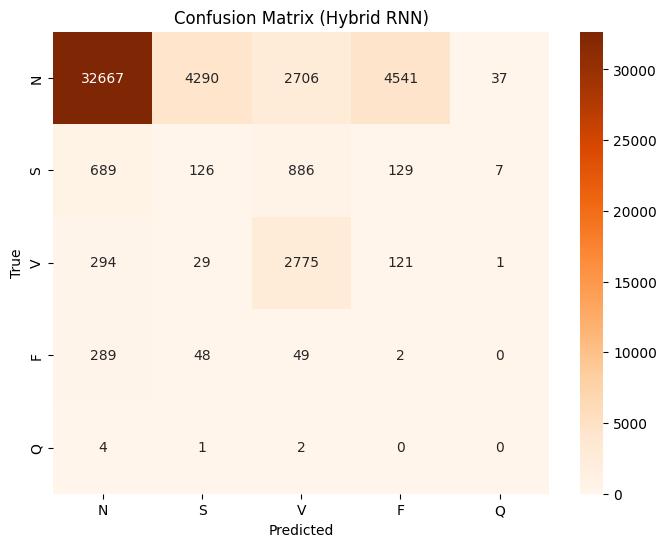

Generating RNN Explanations for: [0, 1, 2, 3, 4]...


RuntimeError: cudnn RNN backward can only be called in training mode

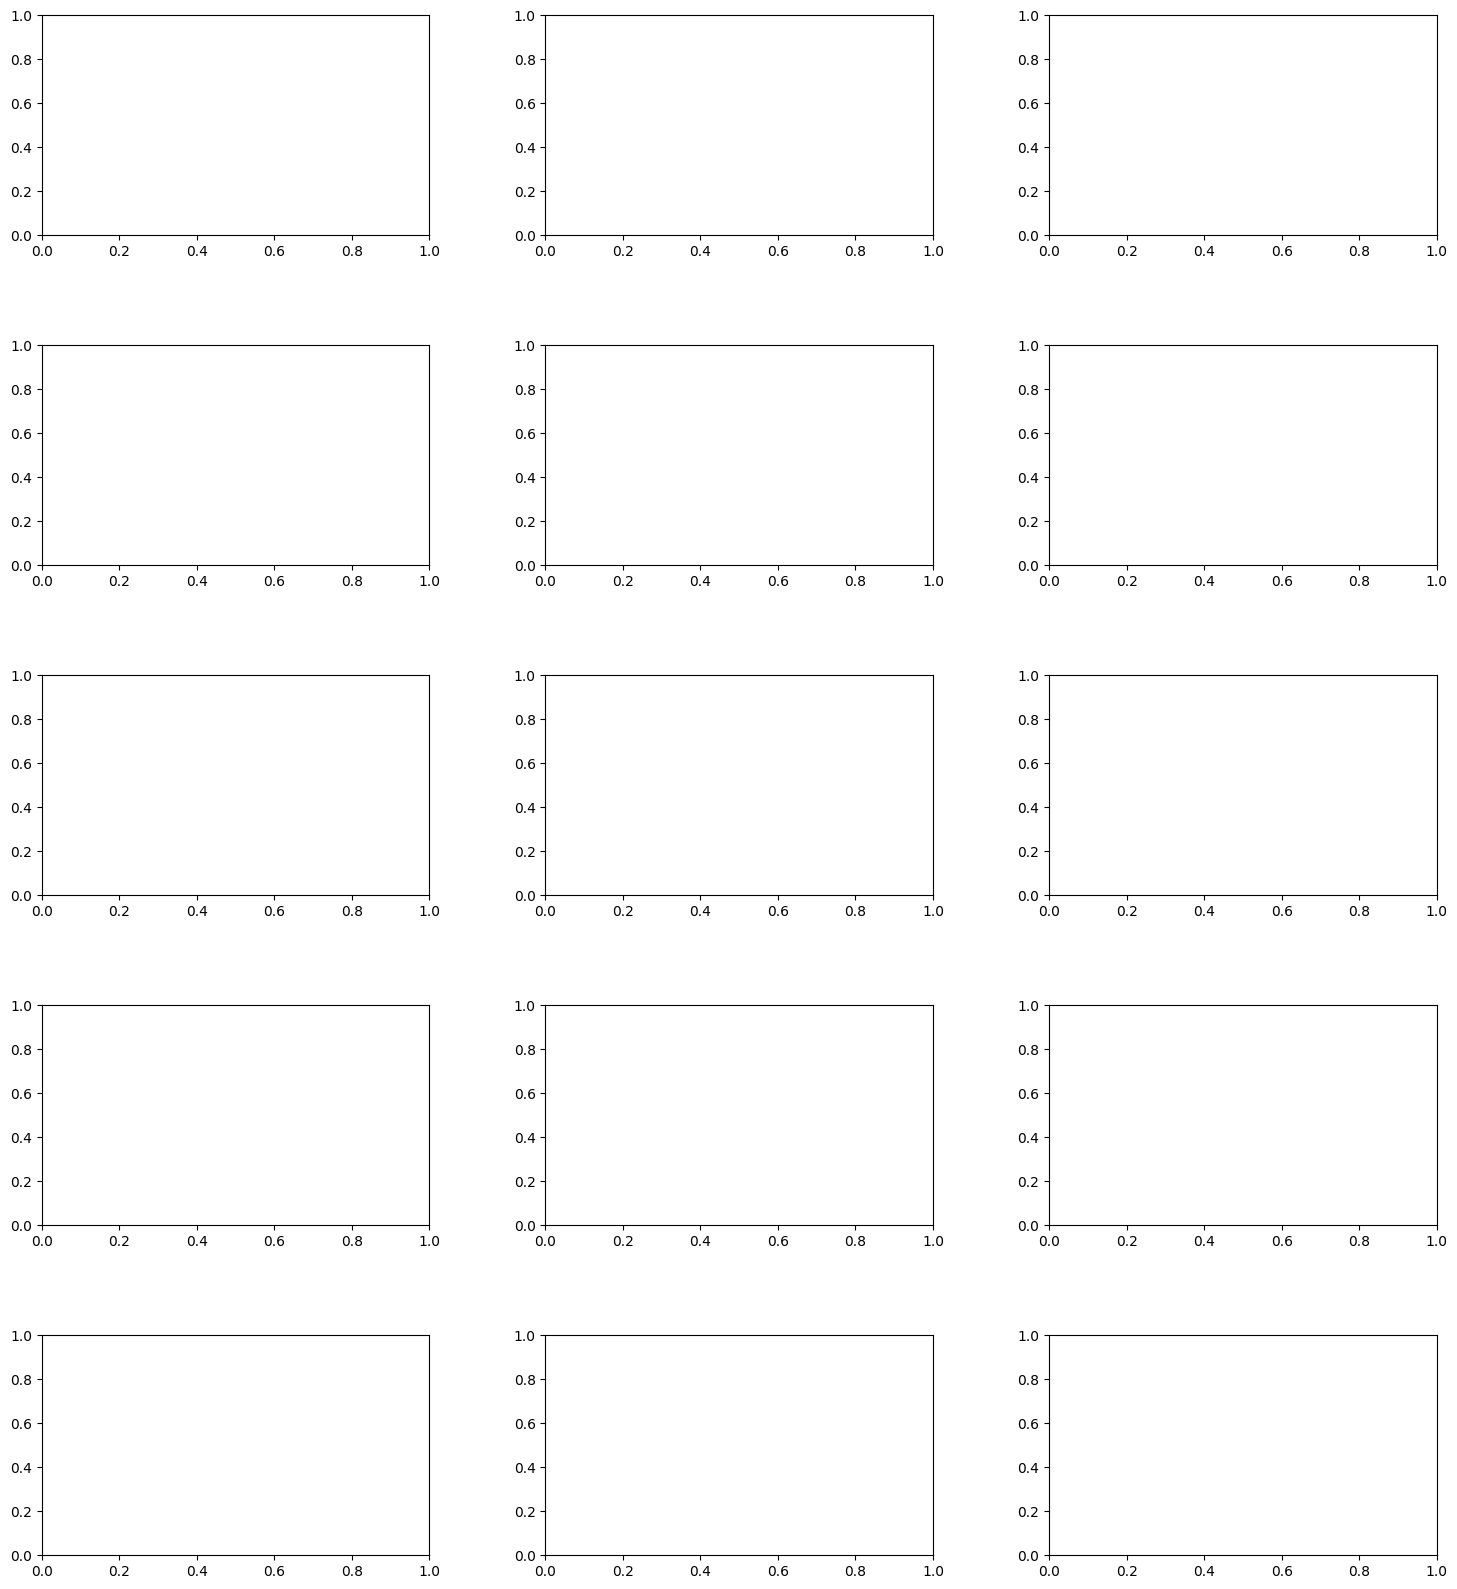

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from scipy.ndimage import zoom

# ==========================================
# 1. DEFINE HYBRID RNN (CNN-LSTM) MODEL
# ==========================================
class HybridRNN(nn.Module):
    def __init__(self):
        super(HybridRNN, self).__init__()
        # CNN Feature Extractor
        self.conv1 = nn.Conv1d(1, 64, 5)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 128, 5)
        self.relu = nn.ReLU()

        # RNN Block (LSTM)
        # Input to LSTM: 128 features (from conv2)
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, batch_first=True)

        # Classifier
        self.fc = nn.Linear(64, 5)

    def forward(self, x):
        # 1. CNN Layers
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # 2. Reshape for LSTM: (Batch, Features, Seq) -> (Batch, Seq, Features)
        x = x.permute(0, 2, 1)

        # 3. LSTM Layer
        # Output is (out, (h_n, c_n))
        _, (hidden, _) = self.lstm(x)

        # 4. Use the last hidden state
        x = hidden[-1]

        # 5. Output
        x = self.fc(x)
        return x

# Initialize
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_rnn = HybridRNN().to(device)
optimizer = optim.Adam(model_rnn.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# ==========================================
# 2. TRAIN THE RNN
# ==========================================
print("Training Hybrid RNN (CNN-LSTM)...")
EPOCHS = 30 # Increase to 10 for Thesis
history = {'loss': [], 'acc': []}

for epoch in range(EPOCHS):
    model_rnn.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_rnn(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    history['loss'].append(epoch_loss)
    history['acc'].append(epoch_acc)
    print(f"Epoch {epoch+1}: Loss {epoch_loss:.4f} | Acc {epoch_acc:.2f}%")

# Plot Training History
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['loss'], 'r-', label='Loss')
plt.title("RNN Training Loss")
plt.subplot(1, 2, 2)
plt.plot(history['acc'], 'b-', label='Accuracy')
plt.title("RNN Training Accuracy")
plt.show()

# ==========================================
# 3. CONFUSION MATRIX
# ==========================================
model_rnn.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_rnn(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

classes = ['N', 'S', 'V', 'F', 'Q']
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (Hybrid RNN)")
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

# ==========================================
# 4. VISUALIZATION (Grad-CAM & Occlusion)
# ==========================================
class GradCAM_RNN:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        # Hooks
        self.handle_b = target_layer.register_full_backward_hook(self.save_gradient)
        self.handle_f = target_layer.register_forward_hook(self.save_activation)

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def save_activation(self, module, input, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        # Temporarily set model to train mode for backward pass
        self.model.train()
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None: class_idx = torch.argmax(output)

        target = output[0, class_idx]
        target.backward()

        # Set model back to eval mode
        self.model.eval()

        # Pool gradients
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2])
        weighted_activations = self.activations[0].clone()

        for i in range(weighted_activations.shape[0]):
            weighted_activations[i, :] *= pooled_gradients[i]

        heatmap = torch.mean(weighted_activations, dim=0).cpu().detach().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0: heatmap /= np.max(heatmap)
        return heatmap, class_idx

    def remove(self):
        self.handle_b.remove()
        self.handle_f.remove()

def get_occlusion_importance(model, input_tensor, target_class, window=4):
    input_tensor = input_tensor.clone()
    with torch.no_grad():
        orig_prob = torch.softmax(model(input_tensor), dim=1)[0, target_class].item()
    importance_map = []
    seq_len = input_tensor.shape[2]
    for i in range(seq_len):
        temp = input_tensor.clone()
        start = max(0, i - window//2)
        end = min(seq_len, i + window//2)
        temp[:, :, start:end] = 0.0
        with torch.no_grad():
            new_prob = torch.softmax(model(temp), dim=1)[0, target_class].item()
        importance_map.append(orig_prob - new_prob)
    return np.array(importance_map)

# Hook Grad-CAM to conv2 (Before LSTM)
grad_cam = GradCAM_RNN(model_rnn, model_rnn.conv2)

# Find samples
found_indices = {}
for cls_idx in range(5):
    indices = np.where(y_test == cls_idx)[0]
    if len(indices) > 0: found_indices[cls_idx] = indices[0]

print(f"Generating RNN Explanations for: {list(found_indices.keys())}...")

fig, axes = plt.subplots(len(found_indices), 3, figsize=(18, 4 * len(found_indices)))
if len(found_indices) == 1: axes = np.expand_dims(axes, 0)
plt.subplots_adjust(hspace=0.5, wspace=0.3)

for i, (cls_idx, idx) in enumerate(found_indices.items()):
    input_tensor = torch.Tensor(X_test[idx]).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    # 1. Grad-CAM
    heatmap, pred_idx = grad_cam.generate(input_tensor, class_idx=cls_idx)
    heatmap_resized = zoom(heatmap, 256/len(heatmap))

    # 2. Occlusion
    imp_values = get_occlusion_importance(model_rnn, input_tensor, cls_idx, window=4)

    signal = X_test[idx].flatten()

    # Plot Signal
    ax1 = axes[i, 0]
    ax1.plot(signal, 'darkorange') # Orange for RNN
    ax1.set_title(f"True: {classes[cls_idx]} | Pred: {classes[pred_idx]}")
    ax1.grid(alpha=0.3)

    # Plot Grad-CAM
    ax2 = axes[i, 1]
    ax2.plot(signal, 'darkorange', alpha=0.3)
    im = ax2.imshow([heatmap_resized], aspect='auto', cmap='YlOrBr', alpha=0.7,
               extent=[0, 256, min(signal), max(signal)])
    ax2.set_title("RNN Attention (via Conv2)")
    plt.colorbar(im, ax=ax2)

    # Plot Occlusion
    ax3 = axes[i, 2]
    cols = ['orange' if x > 0 else 'brown' for x in imp_values]
    ax3.bar(range(len(signal)), imp_values, color=cols, width=1.0)
    ax3.set_title("Feature Importance")
    ax3.grid(alpha=0.3)

grad_cam.remove()
plt.show()

In [ ]:
# Check RAM
from psutil import virtual_memory
ram_gb = virtual_memory().total / 1e9
print('Your Runtime RAM: {:.2f} GB'.format(ram_gb))

# Check CPU info (linux command)
!lscpu | grep 'Model name'

Your Runtime RAM: 13.61 GB
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


In [ ]:
import sys
import tensorflow as tf
import keras
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print(f"Python Version: {sys.version.split()[0]}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version: {keras.__version__}")
# The CUDA version is tricky, but usually ties to TF version.
# If you are on Colab with TF 2.15, CUDA is usually 12.2.
# You can try running this to check: !nvcc --version

Python Version: 3.13.15
TensorFlow Version: 2.20.0
Keras Version: 3.13.2


In [ ]:
import sys
import pandas as pd
import sklearn
import matplotlib
import seaborn
import numpy as np

print("--- COPY THESE NUMBERS INTO YOUR TABLE ---")
print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"Scikit-learn Version: {sklearn.__version__}")
print(f"Matplotlib Version: {matplotlib.__version__}")
print(f"Seaborn Version: {seaborn.__version__}")
print("------------------------------------------")

--- COPY THESE NUMBERS INTO YOUR TABLE ---
Python Version: 3.13.15
NumPy Version: 2.1.3
Pandas Version: 2.2.3
Scikit-learn Version: 1.6.1
Matplotlib Version: 3.10.0
Seaborn Version: 0.13.2
------------------------------------------


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

# --- STEP 1: Define the RNN Model ---
# We use 'rnn_model' to avoid conflicting with your other models
rnn_model = Sequential()
# Input shape automatically adapts to your X_train data (Time Steps, 1)
rnn_model.add(SimpleRNN(64, input_shape=(X_train.shape[1], 1), return_sequences=True))
rnn_model.add(Dropout(0.2))
rnn_model.add(SimpleRNN(32))
rnn_model.add(Dropout(0.2))
rnn_model.add(Dense(5, activation='softmax')) # 5 Classes: N, S, V, F, Q

# --- STEP 2: Compile ---
rnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# --- STEP 3: Train (and capture history for the graph) ---
print("Starting training...")
history_rnn = rnn_model.fit(X_train, y_train,
                            epochs=50,
                            batch_size=32,
                            validation_data=(X_test, y_test),
                            verbose=1)

# --- STEP 4: Generate Graphs (Loss & Accuracy) ---
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Training acc')
    plt.plot(epochs, val_acc, 'r', label='Validation acc')
    plt.title(f'{title} Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title(f'{title} Loss')
    plt.legend()
    plt.show()

plot_history(history_rnn, "RNN")

# --- STEP 5: Generate Confusion Matrix ---
# Get predictions
y_pred_probs = rnn_model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Ensure y_test is in the correct format
if y_test.ndim > 1:
    y_true_classes = np.argmax(y_test, axis=1)
else:
    y_true_classes = y_test

class_names = ['Normal (N)', 'SVEB (S)', 'VEB (V)', 'Fusion (F)', 'Unknown (Q)']

# Plot Heatmap
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('RNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Print Report
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Starting training...
Epoch 1/50


ValueError: Exception encountered when calling SimpleRNNCell.call().

[1mDimensions must be equal, but are 256 and 1 for '{{node sequential_1/simple_rnn_1/simple_rnn_cell_1/MatMul}} = MatMul[T=DT_FLOAT, grad_a=false, grad_b=false, transpose_a=false, transpose_b=false](sequential_1/simple_rnn_1/strided_slice_2, sequential_1/simple_rnn_1/simple_rnn_cell_1/Cast/ReadVariableOp)' with input shapes: [?,256], [1,64].[0m

Arguments received by SimpleRNNCell.call():
  • sequence=tf.Tensor(shape=(None, 256), dtype=float32)
  • states=('tf.Tensor(shape=(None, 64), dtype=float32)',)
  • training=True

Original X_train shape: (51000, 1, 256)
RNN Input shape: (51000, 256, 1)
Starting training...
Epoch 1/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 70s 41ms/step - accuracy: 0.8956 - loss: 0.4171 - val_accuracy: 0.8903 - val_loss: 0.4586
Epoch 2/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 62s 39ms/step - accuracy: 0.8991 - loss: 0.3934 - val_accuracy: 0.8903 - val_loss: 0.4263
Epoch 3/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 89s 44ms/step - accuracy: 0.9060 - loss: 0.3459 - val_accuracy: 0.8907 - val_loss: 0.4810
Epoch 4/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 63s 39ms/step - accuracy: 0.8977 - loss: 0.3946 - val_accuracy: 0.8903 - val_loss: 0.4690
Epoch 5/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 61s 38ms/step - accuracy: 0.9041 - loss: 0.3510 - val_accuracy: 0.8873 - val_loss: 0.4040
Epoch 6/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 61s 38ms/step - accuracy: 0.8993 - loss: 0.3833 - val_accuracy: 0.8903 - val_loss: 0.4472
Epoch 7/30
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 61s 38ms/step - accuracy: 0.8989 - loss: 0.3798 - val_accuracy: 0.8903 -

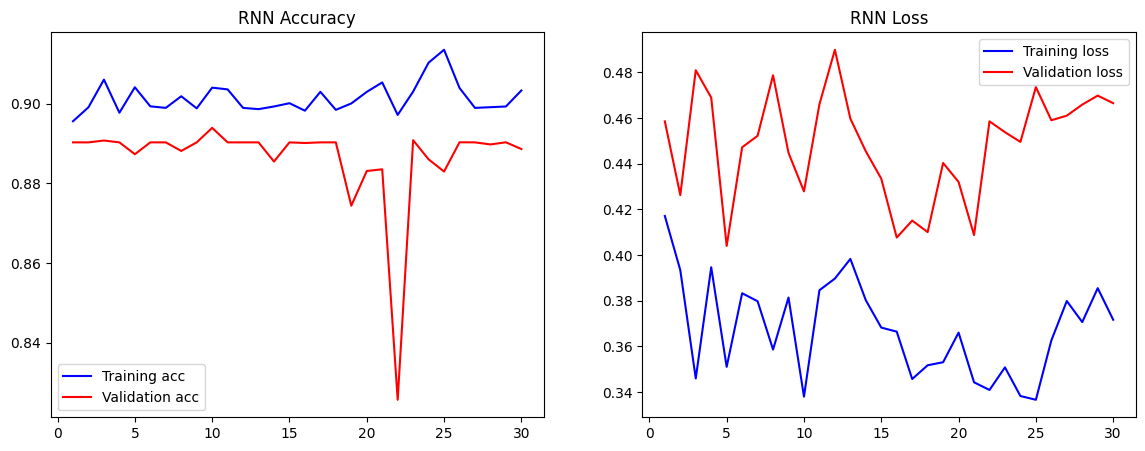

1553/1553 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step


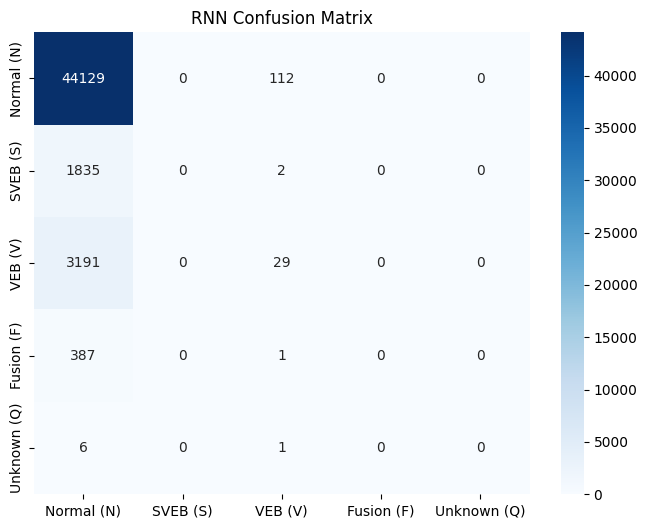

              precision    recall  f1-score   support

  Normal (N)       0.89      1.00      0.94     44241
    SVEB (S)       0.00      0.00      0.00      1837
     VEB (V)       0.20      0.01      0.02      3220
  Fusion (F)       0.00      0.00      0.00       388
 Unknown (Q)       0.00      0.00      0.00         7

    accuracy                           0.89     49693
   macro avg       0.22      0.20      0.19     49693
weighted avg       0.81      0.89      0.84     49693



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

# --- SAFETY CHECK: Ensure Data is Loaded ---
if 'X_train' not in locals():
    raise ValueError("STOP! You must run the 'Data Loading' cells at the top of your notebook first to define X_train and y_train.")

# --- STEP 0: Prepare Data for RNN ---
# RNNs need shape (Samples, Time Steps, Features) -> (N, 256, 1)
# If your data is shaped for CNN (N, 1, 256) or flat (N, 256), we reshape it here.
print(f"Original X_train shape: {X_train.shape}")

if X_train.ndim == 3 and X_train.shape[1] == 1:
    # Convert from (N, 1, 256) to (N, 256, 1)
    X_train_rnn = X_train.reshape(X_train.shape[0], X_train.shape[2], 1)
    X_test_rnn = X_test.reshape(X_test.shape[0], X_test.shape[2], 1)
elif X_train.ndim == 2:
    # Convert from (N, 256) to (N, 256, 1)
    X_train_rnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
    X_test_rnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
else:
    # Assume it is already correct
    X_train_rnn = X_train
    X_test_rnn = X_test

print(f"RNN Input shape: {X_train_rnn.shape}")

# --- STEP 1: Define the RNN Model ---
rnn_model = Sequential()
rnn_model.add(SimpleRNN(64, input_shape=(X_train_rnn.shape[1], 1), return_sequences=True))
rnn_model.add(Dropout(0.2))
rnn_model.add(SimpleRNN(32))
rnn_model.add(Dropout(0.2))
rnn_model.add(Dense(5, activation='softmax'))

# --- STEP 2: Compile ---
rnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

# --- STEP 3: Train ---
print("Starting training...")
history_rnn = rnn_model.fit(X_train_rnn, y_train,
                            epochs=30,
                            batch_size=32,
                            validation_data=(X_test_rnn, y_test),
                            verbose=1)

# --- STEP 4: Plot Graphs ---
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Training acc')
    plt.plot(epochs, val_acc, 'r', label='Validation acc')
    plt.title(f'{title} Accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title(f'{title} Loss')
    plt.legend()
    plt.show()

plot_history(history_rnn, "RNN")

# --- STEP 5: Confusion Matrix ---
y_pred_probs = rnn_model.predict(X_test_rnn)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

if y_test.ndim > 1:
    y_true_classes = np.argmax(y_test, axis=1)
else:
    y_true_classes = y_test

class_names = ['Normal (N)', 'SVEB (S)', 'VEB (V)', 'Fusion (F)', 'Unknown (Q)']

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('RNN Confusion Matrix')
plt.show()

print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))
